In [36]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [37]:
load_dotenv()

True

In [38]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    max_tokens = 200,
)

In [39]:
class JokeState(TypedDict):
    topic: str
    joke: str
    explanation: str

In [40]:
def generate_joke(state: JokeState):
    prompt = f"Generate a joke on the topic {state['topic']}"
    response = llm.invoke(prompt).content

    return {'joke': response}

In [41]:
def generate_explanation(state: JokeState):
    prompt = f"write  explaimation for the joke -{state['joke']}"
    response = llm.invoke(prompt).content
    
    return {'explanation': response}

In [42]:
graph = StateGraph(JokeState)

# add node
graph.add_node('generate_joke',generate_joke)
graph.add_node('generate_explanation',generate_explanation)

# add edge
graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke','generate_explanation')
graph.add_edge('generate_explanation',END)

checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

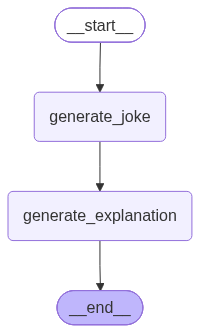

In [43]:
workflow

In [44]:
config1 = {"configurable":{"thread_id":"1"}}
workflow.invoke({'topic':'pizza'}, config= config1)

{'topic': 'pizza',
 'joke': 'Why did the pizza apply for a job?  \n\nBecause it heard the workplace had great *slices* of opportunity and it wanted to *deliver* performance! 🍕😄',
 'explanation': '**Explanation of the joke**\n\n| Part of the joke | What it means literally | Why it’s funny (the wordplay) |\n|------------------|------------------------|--------------------------------|\n| **“Why did the pizza apply for a job?”** | A pizza is an inanimate food item, so it can’t actually look for work. | Sets up the absurd mental image of a pizza writing a résumé, which primes us for a pun. |\n| **“Because it heard the workplace had great *slices* of opportunity…”** | “Slices” refers to the triangular pieces you cut a pizza into. In business‑talk, “slices of opportunity” is a metaphor for “'}

In [45]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?  \n\nBecause it heard the workplace had great *slices* of opportunity and it wanted to *deliver* performance! 🍕😄', 'explanation': '**Explanation of the joke**\n\n| Part of the joke | What it means literally | Why it’s funny (the wordplay) |\n|------------------|------------------------|--------------------------------|\n| **“Why did the pizza apply for a job?”** | A pizza is an inanimate food item, so it can’t actually look for work. | Sets up the absurd mental image of a pizza writing a résumé, which primes us for a pun. |\n| **“Because it heard the workplace had great *slices* of opportunity…”** | “Slices” refers to the triangular pieces you cut a pizza into. In business‑talk, “slices of opportunity” is a metaphor for “'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34b8-c306-6b98-8002-73d4f543c10d'}}, metadata={'source': 'loop', 'step': 2, 'parents':

In [46]:
# intermediate state value
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?  \n\nBecause it heard the workplace had great *slices* of opportunity and it wanted to *deliver* performance! 🍕😄', 'explanation': '**Explanation of the joke**\n\n| Part of the joke | What it means literally | Why it’s funny (the wordplay) |\n|------------------|------------------------|--------------------------------|\n| **“Why did the pizza apply for a job?”** | A pizza is an inanimate food item, so it can’t actually look for work. | Sets up the absurd mental image of a pizza writing a résumé, which primes us for a pun. |\n| **“Because it heard the workplace had great *slices* of opportunity…”** | “Slices” refers to the triangular pieces you cut a pizza into. In business‑talk, “slices of opportunity” is a metaphor for “'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34b8-c306-6b98-8002-73d4f543c10d'}}, metadata={'source': 'loop', 'step': 2, 'parents'

In [47]:
config2 = {'configurable':{'thread_id':"2"}}
workflow.invoke({'topic':'pasta'}, config=config2)

{'topic': 'pasta',
 'joke': 'Why did the spaghetti get a promotion?  \n\nBecause it *always* knows how to *handle* the *pasta*‑tive pressure and never gets tangled in office politics! 🍝😄',
 'explanation': '**Breaking down the joke**\n\n> *Why did the spaghetti get a promotion?*  \n> *Because it **always** knows how to **handle** the **pasta‑tive** pressure and never gets tangled in office politics! 🍝😄*\n\n| Part of the punchline | What it means literally | The word‑play / pun |\n|-----------------------|------------------------|--------------------|\n| **always** | “All the time” | Emphasises that spaghetti is *consistently* good at what it does, a trait employers love. |\n| **handle** | To manage or control something | “Handle” also evokes the *handle* of a fork or a kitchen utensil that you use to lift spaghetti. |\n| **pasta‑tive'}

In [48]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the spaghetti get a promotion?  \n\nBecause it *always* knows how to *handle* the *pasta*‑tive pressure and never gets tangled in office politics! 🍝😄', 'explanation': '**Breaking down the joke**\n\n> *Why did the spaghetti get a promotion?*  \n> *Because it **always** knows how to **handle** the **pasta‑tive** pressure and never gets tangled in office politics! 🍝😄*\n\n| Part of the punchline | What it means literally | The word‑play / pun |\n|-----------------------|------------------------|--------------------|\n| **always** | “All the time” | Emphasises that spaghetti is *consistently* good at what it does, a trait employers love. |\n| **handle** | To manage or control something | “Handle” also evokes the *handle* of a fork or a kitchen utensil that you use to lift spaghetti. |\n| **pasta‑tive'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34b8-d0c9-6bea-8002-8a4d601cc34d'}}, m

In [49]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the spaghetti get a promotion?  \n\nBecause it *always* knows how to *handle* the *pasta*‑tive pressure and never gets tangled in office politics! 🍝😄', 'explanation': '**Breaking down the joke**\n\n> *Why did the spaghetti get a promotion?*  \n> *Because it **always** knows how to **handle** the **pasta‑tive** pressure and never gets tangled in office politics! 🍝😄*\n\n| Part of the punchline | What it means literally | The word‑play / pun |\n|-----------------------|------------------------|--------------------|\n| **always** | “All the time” | Emphasises that spaghetti is *consistently* good at what it does, a trait employers love. |\n| **handle** | To manage or control something | “Handle” also evokes the *handle* of a fork or a kitchen utensil that you use to lift spaghetti. |\n| **pasta‑tive'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34b8-d0c9-6bea-8002-8a4d601cc34d'}}, 

#### Time Travel

In [51]:
workflow.get_state({'configurable':{'thread_id':'1','checkpoint_id': '1f1d34b8-b417-6ae2-8000-4b021201456d'}})

StateSnapshot(values={'topic': 'pizza'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_id': '1f1d34b8-b417-6ae2-8000-4b021201456d'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-29T03:48:03.752823+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34b8-b416-6944-bfff-cdc9d0e38878'}}, tasks=(PregelTask(id='45f3583b-99a8-ea50-86b4-860c8d2ce5b3', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': 'Why did the pizza apply for a job?  \n\nBecause it heard the workplace had great *slices* of opportunity and it wanted to *deliver* performance! 🍕😄'}),), interrupts=())

In [52]:
workflow.invoke(None,{'configurable':{'thread_id':'1','checkpoint_id': '1f1d34b8-b417-6ae2-8000-4b021201456d'}})

{'topic': 'pizza',
 'joke': 'Why did the pizza apply for a job?  \n\nBecause it heard the company was looking for *top* talent and it already had a great *crust*‑om résumé! 🍕😄',
 'explanation': '**Explanation of the joke**\n\n| Part of the joke | What it literally says | The wordplay / pun |\n|------------------|------------------------|--------------------|\n| “Why did the pizza apply for a job?” | Sets up a classic “Why did\u202f…?” joke format, but the subject is a **pizza** instead of a person. | The absurdity of a food item looking for employment is already funny. |\n| “'}

In [54]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?  \n\nBecause it heard the company was looking for *top* talent and it already had a great *crust*‑om résumé! 🍕😄', 'explanation': '**Explanation of the joke**\n\n| Part of the joke | What it literally says | The wordplay / pun |\n|------------------|------------------------|--------------------|\n| “Why did the pizza apply for a job?” | Sets up a classic “Why did\u202f…?” joke format, but the subject is a **pizza** instead of a person. | The absurdity of a food item looking for employment is already funny. |\n| “'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34c1-1d2c-6322-8003-dc1d4ea10029'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-10-29T03:51:49.519615+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34c1-12f6-6f9c-8002-2943934f3e3a'}}, tasks=(), interrupts=()),
 Sta

In [59]:
workflow.update_state(
    config={
        'configurable': {
            'thread_id': '1',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1d34b8-b416-6944-bfff-cdc9d0e38878'
        }
    },
    values={'topic': 'samosa'}
)   

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1d34d2-c2e3-694e-8000-349537b7d103'}}

In [60]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34d2-c2e3-694e-8000-349537b7d103'}}, metadata={'source': 'update', 'step': 0, 'parents': {}}, created_at='2026-10-29T03:59:43.236527+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34b8-b416-6944-bfff-cdc9d0e38878'}}, tasks=(PregelTask(id='2194c7bb-2cfc-304f-db36-08e97bab0a4a', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?  \n\nBecause it heard the company was looking for *top* talent and it already had a great *crust*‑om résumé! 🍕😄', 'explanation': '**Explanation of the joke**\n\n| Part of the joke | What it literally says | The wordplay / pun |\n|------------------|------------------------|--------------------|

In [61]:
workflow.invoke(None,{'configurable':{'thread_id':'1','checkpoint_id': '1f1d34d2-c2e3-694e-8000-349537b7d103'}})

{'topic': 'samosa',
 'joke': 'Why did the samosa apply for a job?  \n\nBecause it heard the position was “crisp‑onally” demanding and it already had the perfect “filling” for success!',
 'explanation': '**The joke broken down, line by line**\n\n| Part of the joke | What it literally says | Why it’s funny (the wordplay) |\n|------------------|------------------------|--------------------------------|\n| **“Why did the samosa apply for a job?”** | A samosa – a deep‑fried Indian snack – is being treated as if it were a person looking for employment. | The humor starts with the absurd image of a piece of food sending a résumé. Anthropomorphising food (giving it human traits) is a classic comedy device. |\n| **'}

In [62]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa', 'joke': 'Why did the samosa apply for a job?  \n\nBecause it heard the position was “crisp‑onally” demanding and it already had the perfect “filling” for success!', 'explanation': '**The joke broken down, line by line**\n\n| Part of the joke | What it literally says | Why it’s funny (the wordplay) |\n|------------------|------------------------|--------------------------------|\n| **“Why did the samosa apply for a job?”** | A samosa – a deep‑fried Indian snack – is being treated as if it were a person looking for employment. | The humor starts with the absurd image of a piece of food sending a résumé. Anthropomorphising food (giving it human traits) is a classic comedy device. |\n| **'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1d34da-2880-65de-8002-f779d1d5c696'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-10-29T04:03:01.796177+00:00', parent_config={'configurabl